### 1. Dataset & ImageNet Mapping Logic
This block includes the dataset loader and a crucial mapping function. Since the models will output a number between 0 and 999, this function translates that specific ImageNet ID back into the dataset's binary labels (0 for cat, 1 for dog).

In [1]:
import os
import time
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from PIL import Image
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

class CustomImageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir)) # 'cat' becomes 0, 'dog' becomes 1
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        self.image_paths = []
        self.labels = []
        
        for cls_name in self.classes:
            cls_dir = os.path.join(root_dir, cls_name)
            if os.path.isdir(cls_dir):
                for img_name in os.listdir(cls_dir):
                    self.image_paths.append(os.path.join(cls_dir, img_name))
                    self.labels.append(self.class_to_idx[cls_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

def map_imagenet_to_binary(imagenet_idx):
    """Maps 1000 ImageNet classes to our binary cat (0) or dog (1) classes."""
    # ImageNet Dog indices: 151 through 268
    if 151 <= imagenet_idx <= 268:
        return 1 
    # ImageNet Cat indices: 281 through 285
    elif 281 <= imagenet_idx <= 285:
        return 0 
    # If the model predicts a car, bird, etc., flag as -1 (incorrect)
    else:
        return -1

### 2. Original Pre-Trained Model Initialization
Notice that we are no longer altering m.fc or m.classifier. The models are left completely intact. We also extract the categories meta-data so we know the exact English names (like "Egyptian cat" or "Golden Retriever") the model is predicting.

In [2]:
def get_original_pretrained_models():
    """Loads models intact with all 1,000 original ImageNet classes."""
    models_dict = {}
    
    # 1. ResNet-18
    weights1 = models.ResNet18_Weights.DEFAULT
    models_dict['ResNet-18'] = {
        'model': models.resnet18(weights=weights1), 
        'transform': weights1.transforms(),
        'categories': weights1.meta["categories"]
    }
    
    # 2. MobileNet V3 Small
    weights2 = models.MobileNet_V3_Small_Weights.DEFAULT
    models_dict['MobileNetV3'] = {
        'model': models.mobilenet_v3_small(weights=weights2), 
        'transform': weights2.transforms(),
        'categories': weights2.meta["categories"]
    }
    
    # 3. EfficientNet-B0
    weights3 = models.EfficientNet_B0_Weights.DEFAULT
    models_dict['EfficientNet-B0'] = {
        'model': models.efficientnet_b0(weights=weights3), 
        'transform': weights3.transforms(),
        'categories': weights3.meta["categories"]
    }
    
    # 4. SqueezeNet 1.0
    weights4 = models.SqueezeNet1_0_Weights.DEFAULT
    models_dict['SqueezeNet'] = {
        'model': models.squeezenet1_0(weights=weights4), 
        'transform': weights4.transforms(),
        'categories': weights4.meta["categories"]
    }
    
    # 5. DenseNet-121
    weights5 = models.DenseNet121_Weights.DEFAULT
    models_dict['DenseNet-121'] = {
        'model': models.densenet121(weights=weights5), 
        'transform': weights5.transforms(),
        'categories': weights5.meta["categories"]
    }
    
    return models_dict

### 3. Evaluation Using the Mapped Labels
The evaluation loop now intercepts the 1,000-class prediction, uses our mapping function to convert it to a 0 or 1, and then scores it against the actual dataset folder name.

Evaluating ResNet-18 on original 1000 classes...
Evaluating MobileNetV3 on original 1000 classes...
Evaluating EfficientNet-B0 on original 1000 classes...
Evaluating SqueezeNet on original 1000 classes...
Evaluating DenseNet-121 on original 1000 classes...

--- Pre-trained Model Evaluation (Mapped Classes) ---
| Model           |   Accuracy |   Precision |   Recall |   F1-Score |   Inference Time (s) |
|:----------------|-----------:|------------:|---------:|-----------:|---------------------:|
| ResNet-18       |      0.841 |    0.631246 | 0.560667 |   0.58927  |             19.7592  |
| MobileNetV3     |      0.822 |    0.620456 | 0.548    |   0.57569  |              6.46546 |
| EfficientNet-B0 |      0.893 |    0.64495  | 0.595333 |   0.617549 |             23.4781  |
| SqueezeNet      |      0.739 |    0.588723 | 0.492667 |   0.516905 |             21.7545  |
| DenseNet-121    |      0.882 |    0.646786 | 0.588    |   0.614353 |             49.7572  |


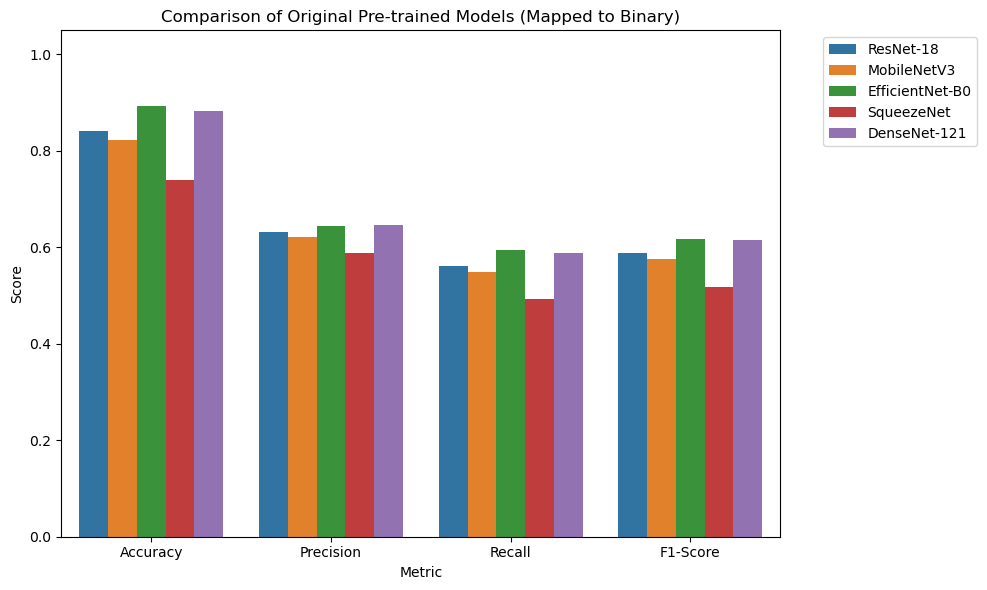

In [13]:
def evaluate_original_models(data_dir):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    models_dict = get_original_pretrained_models()
    results = []
    
    for name, config in models_dict.items():
        print(f"Evaluating {name} on original 1000 classes...")
        model = config['model'].to(device)
        model.eval() 
        
        dataset = CustomImageDataset(root_dir=data_dir, transform=config['transform'])
        dataloader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)
        
        all_mapped_preds = []
        all_labels = []
        
        start_time = time.time()
        
        with torch.no_grad(): 
            for images, labels in dataloader:
                images, labels = images.to(device), labels.to(device)
                
                outputs = model(images)
                _, raw_preds = torch.max(outputs, 1) # Predicts 0-999
                
                # Map the raw ImageNet prediction (e.g., 285) to binary (0 or 1)
                for p in raw_preds:
                    all_mapped_preds.append(map_imagenet_to_binary(p.item()))
                    
                all_labels.extend(labels.cpu().numpy())
                
        inference_time = time.time() - start_time
        
        acc = accuracy_score(all_labels, all_mapped_preds)
        prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_mapped_preds, average='macro', zero_division=0)
        
        results.append({
            'Model': name,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'Inference Time (s)': inference_time
        })
        
    return pd.DataFrame(results)

# Run the evaluation and plot the results
if __name__ == "__main__":
    DATA_DIR = r"D:\dataset_root"
    df_results = evaluate_original_models(DATA_DIR)
    
    print("\n--- Pre-trained Model Evaluation (Mapped Classes) ---")
    print(df_results.to_markdown(index=False))
    
    df_melted = df_results.melt(
        id_vars='Model', 
        value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score'], 
        var_name='Metric', 
        value_name='Score'
    )
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model')
    
    plt.title('Comparison of Original Pre-trained Models (Mapped to Binary)')
    plt.ylim(0, 1.05)
    

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    
    plt.savefig('portfolio_pretrained_mapped_comparison.png')
    plt.show()

**Top Overall Performer**: EfficientNet-B0 is the best model in this evaluation, achieving the highest Accuracy (89.3%) and the highest F1-Score (0.617) while maintaining a reasonable inference time of 23.47 seconds.   

**Best for Speed**: MobileNetV3 is highly optimized for speed, completing inference in just 6.46 seconds while still delivering a strong 82.2% accuracy.   

**High Accuracy but Slowest**: DenseNet-121 performs very well with an 88.2% accuracy, but it is the most computationally heavy, taking 49.75 seconds to run—making it the slowest by a wide margin.   

**Weakest Performer**: SqueezeNet struggled the most across all metrics, recording the lowest Accuracy (73.9%) and the lowest F1-Score (0.516).   

### 4. Visualization Helper (Showing Specific ImageNet Names)
Run this setup block. It compares the actual folder name against the highly specific label the model produces (e.g., Folder: cat vs Model: Siamese cat).

In [7]:
def show_detailed_predictions(model_name, num_images=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    data_dir = r"D:\dataset_root"
    classes = sorted(os.listdir(data_dir))
    
    models_dict = get_original_pretrained_models()
    config = models_dict[model_name]
    model = config['model'].to(device)
    model.eval() 
    
    dataset = CustomImageDataset(root_dir=data_dir, transform=config['transform'])
    indices = random.sample(range(len(dataset)), num_images)
    
    fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
    fig.suptitle(f"{model_name} - Pre-Trained ImageNet Predictions", fontsize=16, y=1.2)
    
    with torch.no_grad():
        for i, idx in enumerate(indices):
            img_path = dataset.image_paths[idx]
            orig_img = Image.open(img_path).convert("RGB")
            
            tensor_img, actual_label_idx = dataset[idx]
            tensor_img = tensor_img.unsqueeze(0).to(device)
            
            output = model(tensor_img)
            _, pred_idx = torch.max(output, 1)
            
            # Extract the actual English word the model guessed (e.g., "Maltese dog")
            raw_pred_val = pred_idx.item()
            specific_imagenet_label = config['categories'][raw_pred_val]
            mapped_binary_pred = map_imagenet_to_binary(raw_pred_val)
            
            is_correct = (mapped_binary_pred == actual_label_idx)
            color = 'green' if is_correct else 'red'
            
            axes[i].imshow(orig_img)
            axes[i].axis('off')
            
            # Format the text to show the broad category vs the specific guess
            title_text = f"Folder: {classes[actual_label_idx]}\nGuess: {specific_imagenet_label}"
            axes[i].set_title(title_text, color=color, fontweight='bold', fontsize=10)
            
    plt.show()

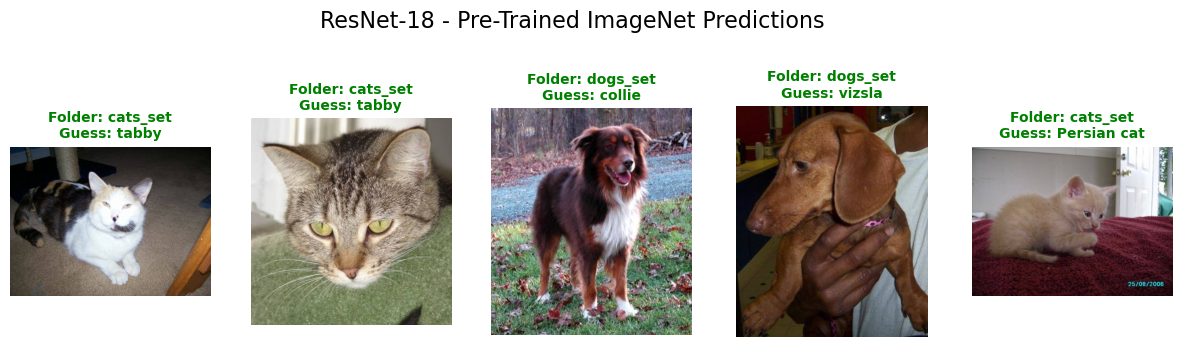

In [15]:
show_detailed_predictions('ResNet-18')

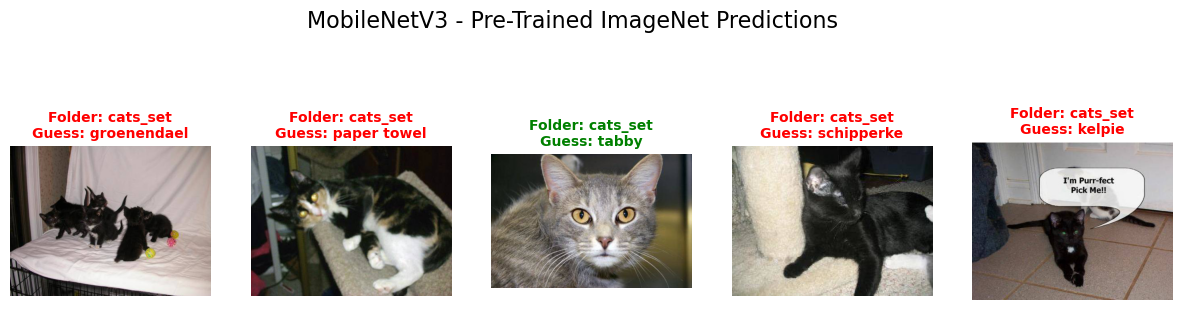

In [16]:
show_detailed_predictions('MobileNetV3')

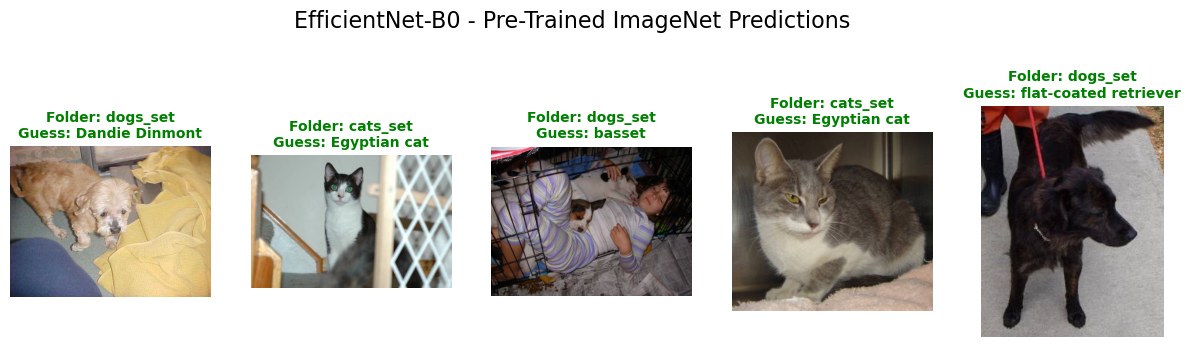

In [17]:
show_detailed_predictions('EfficientNet-B0')

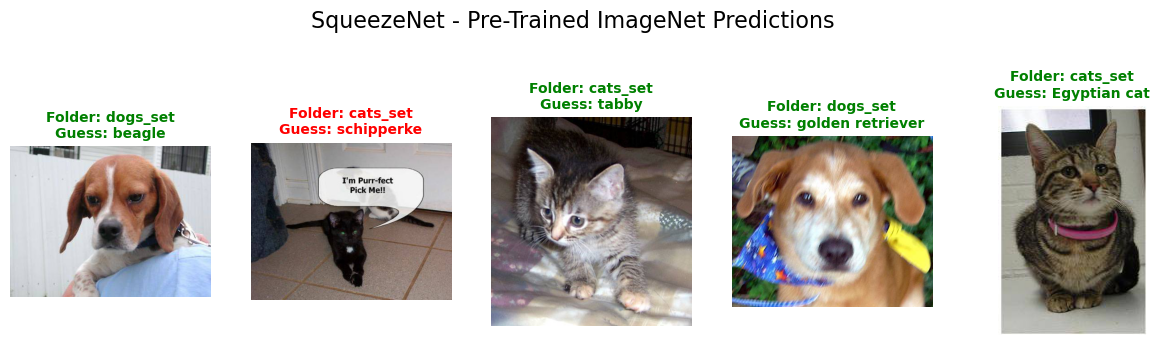

In [18]:
show_detailed_predictions('SqueezeNet')

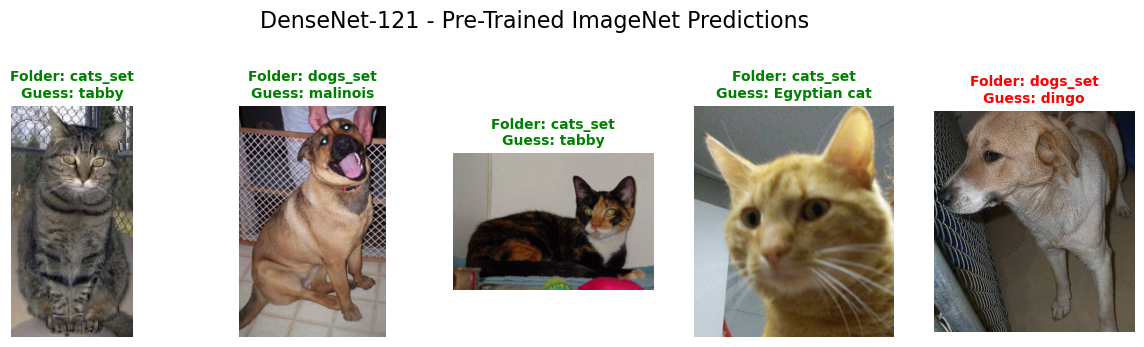

In [14]:
show_detailed_predictions('DenseNet-121')